In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(
    r'C:\Users\zhao\Desktop\数据分析\UserBehavior.csv',
    header=None,
    names = ['user_id','item_id','category_id','behavior_type','timestamp'],
    nrows = 1000000)


In [4]:
print(df.head())

   user_id  item_id  category_id behavior_type   timestamp
0        1  2268318      2520377            pv  1511544070
1        1  2333346      2520771            pv  1511561733
2        1  2576651       149192            pv  1511572885
3        1  3830808      4181361            pv  1511593493
4        1  4365585      2520377            pv  1511596146


In [5]:
print(df.info)

<bound method DataFrame.info of         user_id  item_id  category_id behavior_type   timestamp
0             1  2268318      2520377            pv  1511544070
1             1  2333346      2520771            pv  1511561733
2             1  2576651       149192            pv  1511572885
3             1  3830808      4181361            pv  1511593493
4             1  4365585      2520377            pv  1511596146
...         ...      ...          ...           ...         ...
999995   128600  1729257      2640118          cart  1511826553
999996   128600  4935668      2640118          cart  1511826588
999997   128600  3175221      2640118          cart  1511826676
999998   128600  3840425      2640118            pv  1511826695
999999   128600  2495970      2640118          cart  1511826739

[1000000 rows x 5 columns]>


In [6]:
print(f'用户数:{df["user_id"].nunique()}')
print(f'商品数:{df["item_id"].nunique()}')

用户数:9739
商品数:399114


In [7]:
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df['date'] = df['datetime'].dt.date
df['hour'] = df['datetime'].dt.hour
df['weekday'] = df['datetime'].dt.weekday

In [8]:
# 统计行为类型数量和占比
print(df['behavior_type'].value_counts())
print(df['behavior_type'].value_counts(normalize=True))

behavior_type
pv      896106
cart     55447
fav      28088
buy      20359
Name: count, dtype: int64
behavior_type
pv      0.896106
cart    0.055447
fav     0.028088
buy     0.020359
Name: proportion, dtype: float64


##漏斗分析

In [9]:
step = ['pv','cart','fav','buy']
uv = df.groupby('behavior_type')['user_id'].nunique()

In [10]:
funnel_df = pd.DataFrame({
    'step':step,
    'uv':[uv.get(step,0) for
          step in step]}
)

In [11]:
funnel_df['abs_rate'] = funnel_df['uv']/funnel_df.loc[0,'uv']
funnel_df['step_rate'] = funnel_df['uv']/funnel_df['uv'].shift(1)
funnel_df.loc[0,'step_rate'] = 1.0


In [12]:
funnel_df['drop_uv'] = funnel_df['uv'] - funnel_df['uv'].shift(1)

<BarContainer object of 4 artists>

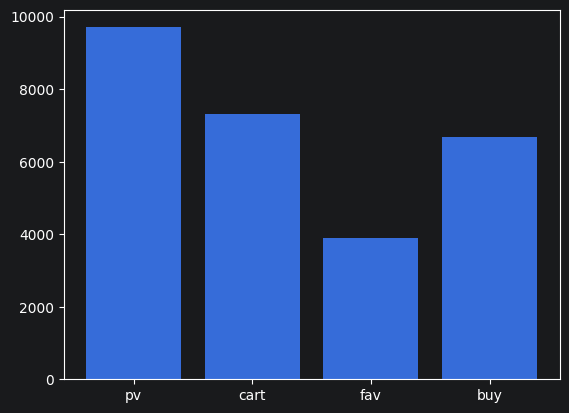

In [15]:
plt.bar(funnel_df['step'], funnel_df['uv'])

##RFM用户价值

In [18]:
buy_df = df[df['behavior_type'] == 'buy'].copy()
print(f'有效用户数:{buy_df["user_id"].nunique()}')

有效用户数:6689


In [19]:
end_date = buy_df['date'].max()
print(f'截止日期:{end_date}')

截止日期:2017-12-03


In [20]:
rfm = buy_df.groupby('user_id').agg(
    R = ('date',lambda x: (end_date - x.max()).days),
    F = ('behavior_type','count'),
    M = ('item_id','nunique')
).reset_index()

In [22]:
print(rfm.describe())

            user_id            R            F            M
count  6.689000e+03  6689.000000  6689.000000  6689.000000
mean   4.339164e+05     2.595306     3.043654     2.891165
std    4.365204e+05     2.420367     3.250811     2.924712
min    1.000000e+02     0.000000     1.000000     1.000000
25%    1.092760e+05     1.000000     1.000000     1.000000
50%    1.220460e+05     2.000000     2.000000     2.000000
75%    1.005522e+06     4.000000     4.000000     4.000000
max    1.018011e+06     9.000000    72.000000    66.000000


In [23]:
rfm['R_score'] = np.where(rfm['R'] <= rfm['R'].mean(), 1, 0)
rfm['F_score'] = np.where(rfm['F'] >= rfm['F'].mean(), 1, 0)
rfm['M_score'] = np.where(rfm['M'] >= rfm['M'].mean(), 1, 0)

In [24]:
rfm['rfm_group'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

# 定义分层规则（完全对应文档里的RFM分层逻辑）
rfm_rule = {
    '111': '重要价值用户（R近+F频高+M额高）',
    '110': '重要深耕用户（R近+F频高+M额低）',
    '101': '一般价值用户（R近+F频低+M额高）',
    '100': '一般发展用户（R近+F频低+M额低）',
    '011': '重要唤回用户（R远+F频高+M额高）',
    '010': '重要挽留用户（R远+F频高+M额低）',
    '001': '一般唤回用户（R远+F频低+M额高）',
    '000': '一般维持用户（R远+F频低+M额低）'
}
rfm['user_level'] = rfm['rfm_group'].map(rfm_rule)

In [25]:
level_count = rfm['user_level'].value_counts().reset_index()
level_count.columns = ['用户层级', '用户数']
level_count['占比'] = (level_count['用户数'] / level_count['用户数'].sum()).round(4) * 100

print(level_count)

                 用户层级   用户数     占比
0  一般维持用户（R远+F频低+M额低）  2114  31.60
1  一般发展用户（R近+F频低+M额低）  1826  27.30
2  重要价值用户（R近+F频高+M额高）  1375  20.56
3  一般价值用户（R近+F频低+M额高）   582   8.70
4  重要唤回用户（R远+F频高+M额高）   426   6.37
5  一般唤回用户（R远+F频低+M额高）   353   5.28
6  重要挽留用户（R远+F频高+M额低）     7   0.10
7  重要深耕用户（R近+F频高+M额低）     6   0.09


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
plt.rcParams['font.sans-serif'] = ['SimHei','Microsoft YaHei','KaiTi']
plt.rcParams['axes.unicode_minus'] = False

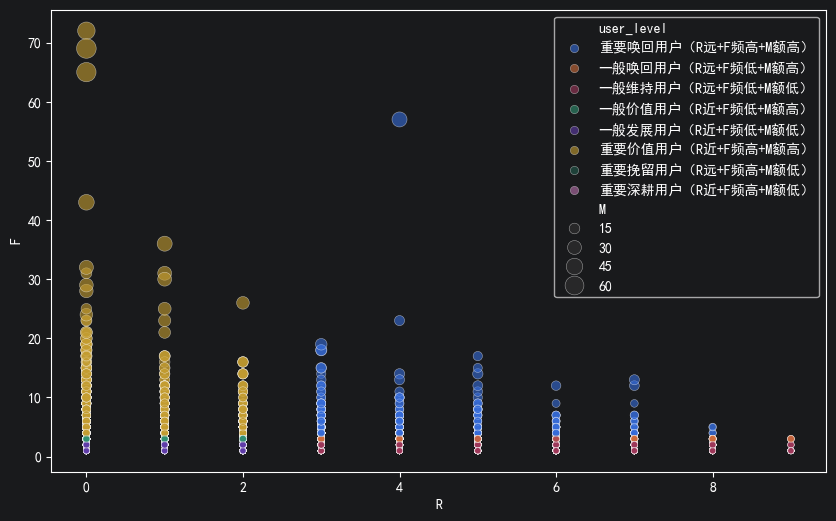

In [30]:
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(
    data=rfm,
    x='R', y='F',
    size='M',
    hue='user_level',
    sizes=(20, 200),
    alpha=0.6
)

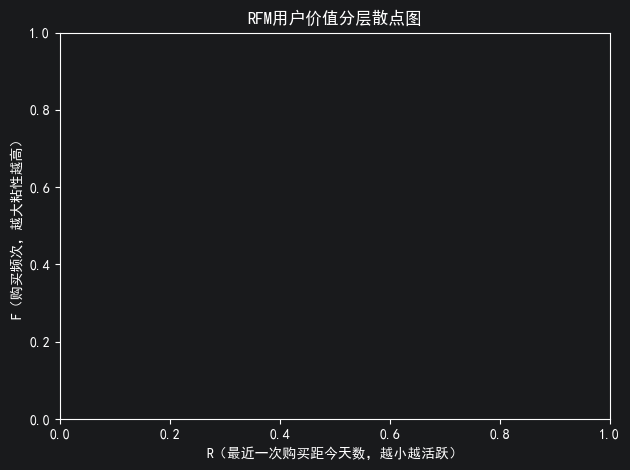

In [32]:
plt.title('RFM用户价值分层散点图')
plt.xlabel('R（最近一次购买距今天数，越小越活跃）')
plt.ylabel('F（购买频次，越大粘性越高）')
plt.tight_layout()
plt.show()